In [3]:
import eurostat
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

class EuroStatExplorer:
    """Explore, retrieve, and visualize Eurostat data."""

    def __init__(self):
        """Load the Eurostat dataset catalogue."""
        self.toc_df = eurostat.get_toc_df()
        self.raw_data = None

    def search_dataset(self, keyword):
        """Search for datasets matching a keyword."""
        return eurostat.subset_toc_df(self.toc_df, keyword)

    def get_parameters(self, dataset_code):
        """Retrieve the dimensions of a dataset."""
        return eurostat.get_pars(dataset_code)

    def load_dataset(self, dataset_code):
        """Retrieve a dataset from Eurostat."""
        self.raw_data = eurostat.get_data_df(dataset_code)
        return self.raw_data

    def inspect_dataset(self):
        """Display basic information about loaded data."""
        if self.raw_data is None:
            raise ValueError("Load a dataset before inspecting it.")

        print("Shape:", self.raw_data.shape)
        print("Columns:", self.raw_data.columns.tolist())
        print("Data types:")
        print(self.raw_data.dtypes)
        print("First observations:")
        print(self.raw_data.head())

    def plot_line(self, data, title, xlabel, ylabel):
        """Create a line chart from a prepared DataFrame."""
        ax = data.plot(kind="line", marker="o", figsize=(10, 5))
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        plt.tight_layout()
        plt.show()

    def plot_bar(self, data, x, y, title, xlabel, ylabel):
        """Create a bar chart from a prepared DataFrame."""
        plt.figure(figsize=(10, 5))
        sns.barplot(data=data, x=x, y=y)
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    def plot_scatter(self, data, x, y, title, xlabel, ylabel):
        """Create a scatterplot from a prepared DataFrame."""
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=data, x=x, y=y)
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        plt.tight_layout()
        plt.show()

    def plot_histogram(self, data, column, title, xlabel):
        """Create a histogram of a numerical variable."""
        values = pd.to_numeric(data[column], errors="coerce").dropna()
        plt.figure(figsize=(8, 5))
        sns.histplot(values, bins=15, kde=True)
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()





In [4]:
es = EuroStatExplorer()


es.get_parameters("nama_10_a64")
dataset4 =es.load_dataset("nama_10_a64")
es.inspect_dataset()

Shape: (294230, 56)
Columns: ['freq', 'unit', 'nace_r2', 'na_item', 'geo\\TIME_PERIOD', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
Data types:
freq                   str
unit                   str
nace_r2                str
na_item                str
geo\TIME_PERIOD        str
1975               float64
1976               float64
1977               float64
1978               float64
1979               float64
1980               float64
1981               float64
1982               float64
1983               float64
1984               float64
1985               float64
1986               float64
1987               float64
1988  

In [5]:

transposed_dataset4 = dataset4.T

dataset4_pop = transposed_dataset4
dataset4_df = transposed_dataset4.iloc[45:58].copy()
dataset4_df.columns = transposed_dataset4.iloc[4].tolist()

print(dataset4_df)


          AL      AT      BE      BG      CH     CY      CZ       DE      DK  \
2015  1649.8  3449.2  3758.9  1302.8  2862.5  256.7  2197.0  17612.3  2378.7   
2016  1713.6  3629.3  3482.3  1400.1  2922.6  299.1  2310.6  18284.5  2020.9   
2017  1666.0  3591.6  3651.3  1518.5  2877.0  278.6  2218.4  19100.8  2330.5   
2018  1689.1  3693.9  3318.1  1491.2  3055.9  271.6  2292.8  16563.4  2320.8   
2019  1727.1  3640.4  3468.5  1520.9  2973.2  288.3  2398.9  18053.8  2399.9   
2020  1758.2  3528.7  3336.2  1480.2  2940.3  282.0  2564.2  18021.3  2460.0   
2021  1728.7  3735.6  3304.8  1925.1  2758.3  267.5  2214.0  21286.8  2612.9   
2022  1645.4  3920.0  3202.7  1786.0  3066.4  230.0  2242.4  21843.7  2348.8   
2023  1623.8  3860.3  3599.6  1512.3  3081.8  230.9  2688.8  19362.1  2088.7   
2024  1614.1  3905.0  3604.3  1622.1  3016.0  258.1  2633.6  18662.9  1948.9   
2025  1573.8  3949.4  3661.8     NaN     NaN  260.3  2700.4  18915.2  1999.2   

          EA12  ...   LU   MT   NL   NO

In [4]:
countries = ["PT", "NL", "IT"]

dataset4_filtered = dataset4_df[countries]
print(dataset4_filtered)
mask = dataset4_df.columns.str[:2].isin(countries)
dataset4_ports = dataset4_df.loc["2015":"2025", mask]
print(dataset4_ports)


          PT     PT      PT     PT     PT    PT     PT    PT     PT     PT  \
2015  3641.5  737.2  2846.5  623.0  574.7  84.1  251.8  32.6  492.5  133.1   
2016  3634.1  752.5  2779.1  634.0  602.0  86.2  271.8  34.2  529.3  125.5   
2017  3702.5  759.9  2905.9  642.3  533.5  88.2  296.2  32.5  533.2  119.1   
2018  3693.4  774.6  2891.1  656.1  538.0  90.6  296.1  31.8  541.2  120.3   
2019  3845.8  790.6  3079.8  673.0  512.7  91.1  299.3  31.3  524.9  130.3   
2020  3791.4  806.5  2971.9  689.6  571.9  91.6  276.9  30.9  517.6  142.0   
2021  3972.1  820.0  3067.0  705.1  602.6  90.4  326.9  31.0  504.6  146.0   
2022  3661.1  837.2  2736.7  728.3  596.8  87.6  328.4  29.8  428.0  152.3   
2023  3592.2  857.3  2700.8  752.5  588.2  85.1  306.8  29.5  437.1  155.6   
2024  3675.8  851.8  2800.8  750.2  566.5  83.7  321.7  28.4  440.1  165.7   
2025  3643.6  902.0     NaN    NaN    NaN   NaN    NaN   NaN  471.5  175.4   

      ...       IT      IT       IT   IT         IT        IT  

In [6]:
def gva_table(df, nace, countries=("PT", "NL", "IT"), na_item="B1G", unit="CP_MEUR"):
    """Return one industry's gross value added: rows = years 2015–2025, columns = countries."""
    geo_col = df.columns[4]                      
    sel = df[(df["nace_r2"] == nace) &
             (df["na_item"] == na_item) &       
             (df["unit"] == unit) &             
             (df[geo_col].isin(countries))]
    t = sel.T
    out = t.iloc[5:].copy()                      
    out.columns = t.iloc[4].tolist()           
    out = out.apply(pd.to_numeric, errors="coerce")
    return out.loc["2014":"2024"]

gva_h50 = gva_table(dataset4, "H50")      
gva_h52 = gva_table(dataset4, "H52")      
gva_total = gva_table(dataset4, "TOTAL")  


In [7]:
print(gva_h52)

           IT       NL      PT
2014  30303.3  10600.0  2805.3
2015  29783.1  11237.0  3008.8
2016  30687.5  11086.0  3158.4
2017  31931.2  11787.0  3472.1
2018  33247.4  12249.0  3602.5
2019  33472.0  12932.0  3860.5
2020  29215.1  12478.0  2877.7
2021  34271.2  13950.0  3232.0
2022  39401.2  17429.0  4072.0
2023  40912.7  17733.0  4547.7
2024  44120.3  18484.0  4960.1


In [8]:
print(gva_h50)

          IT      NL     PT
2014  3489.8  2752.0  132.7
2015  3969.8  3100.0  132.5
2016  3779.5  2791.0  129.2
2017  3894.0  2825.0  131.0
2018  3743.9  2768.0  120.1
2019  3954.0  2864.0  155.7
2020  1637.8  2901.0  125.3
2021  2200.9  3413.0  173.6
2022  3222.9  4928.0  240.5
2023  5085.6  5084.0  235.1
2024  5025.9  4931.0  253.1


In [9]:
COUNTRIES = ["PT", "IT", "NL"]
NAMES = {"PT": "Portugal", "IT": "Italy", "NL": "Netherlands"}
THEME = "Ocean"   # choose: "Ocean", "Forest", "Sunset"
themes = {"Ocean": ["#6696b3", "#d2a071", "#69a89d"],
          "Forest": ["#75957a", "#b3b97b", "#bc957d"],
          "Sunset": ["#b27d91", "#daa47d", "#909cbd"]}
palette = themes[THEME]
color_map = dict(zip(COUNTRIES, palette))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

def prep(df):
    """Years as numbers (2014…2024) and the countries always in the same order."""
    t = df.copy()
    t.index = t.index.astype(int)
    t.index.name = "year"
    t.columns.name = "country"
    return t.reindex(columns=COUNTRIES)

# Current prices (CP_MEUR, € million): for shares within a year
h50_cp = prep(gva_h50)
h52_cp = prep(gva_h52)
total_cp = prep(gva_total)
h_cp = prep(gva_table(dataset4, "H"))            # all transportation and storage
port_cp = h50_cp + h52_cp

# Real terms (chain-linked volumes): for growth over time. Use the CLV unit with the fewest gaps
clv = [u for u in dataset4["unit"].unique() if u.startswith("CLV") and u.endswith("_MEUR")]
def gaps(u):
    return int(prep(gva_table(dataset4, "H50", unit=u)).isna().sum().sum()
               + prep(gva_table(dataset4, "H52", unit=u)).isna().sum().sum())
REAL = min(clv, key=lambda u: (gaps(u), -int(u[3:5])))
h50_real = prep(gva_table(dataset4, "H50", unit=REAL))
h52_real = prep(gva_table(dataset4, "H52", unit=REAL))
total_real = prep(gva_table(dataset4, "TOTAL", unit=REAL))
port_real = h50_real + h52_real
print("Real-terms unit used:", REAL, "| missing values:", gaps(REAL))

# Goods handled in ports (mar_mg_aa_cwh, thousand tonnes) – small download, to link GVA with cargo
cwh = eurostat.get_data_df("mar_mg_aa_cwh", filter_pars={"unit": ["THS_T"], "rep_mar": COUNTRIES})
geo_m = [c for c in cwh.columns if "TIME_PERIOD" in c][0]
tonnes = prep(cwh.set_index(geo_m)[[str(y) for y in range(2014, 2025)]].T)

print("\nMissing values (current prices):", {"H50": h50_cp.isna().sum().to_dict(),
                                              "H52": h52_cp.isna().sum().to_dict(),
                                              "TOTAL": total_cp.isna().sum().to_dict()})

Real-terms unit used: CLV20_MEUR | missing values: 0

Missing values (current prices): {'H50': {'PT': 0, 'IT': 0, 'NL': 0}, 'H52': {'PT': 0, 'IT': 0, 'NL': 0}, 'TOTAL': {'PT': 0, 'IT': 0, 'NL': 0}}


In [10]:
# ===== INDICATORS: dependency, structure and value per tonne =====
h50_share = h50_cp / total_cp * 100              # % of the economy's GVA
h52_share = h52_cp / total_cp * 100
port_share = port_cp / total_cp * 100
port_in_h = port_cp / h_cp * 100                 # % of all transportation and storage
h50_in_port = h50_cp / port_cp * 100             # shipping's part of H50 + H52
eur_per_tonne = port_cp * 1e6 / (tonnes * 1000)  # € of H50 + H52 GVA per tonne handled (nominal)

summary = pd.DataFrame({
    "H50 % of GVA": h50_share.mean(),
    "H52 % of GVA": h52_share.mean(),
    "H50+H52 % of GVA": port_share.mean(),
    "H50+H52 % of transport (H)": port_in_h.mean(),
    "H50 % of H50+H52": h50_in_port.mean(),
    "€ per tonne handled": eur_per_tonne.mean(),
    f"H50+H52 real growth 2014–2024 (%)": (port_real.loc[2024] / port_real.loc[2014] - 1) * 100,
    f"total GVA real growth 2014–2024 (%)": (total_real.loc[2024] / total_real.loc[2014] - 1) * 100,
}).rename(index=NAMES).round(2)
print("Averages 2014–2024")
print(summary.T)

Averages 2014–2024
country                              Portugal  Italy  Netherlands
H50 % of GVA                             0.09   0.22         0.45
H52 % of GVA                             1.92   2.09         1.79
H50+H52 % of GVA                         2.00   2.31         2.24
H50+H52 % of transport (H)              42.25  46.61        47.77
H50 % of H50+H52                         4.37   9.53        20.20
€ per tonne handled                     44.03  78.55        29.88
H50+H52 real growth 2014–2024 (%)       40.71  13.23        21.23
total GVA real growth 2014–2024 (%)     23.53  13.42        22.00


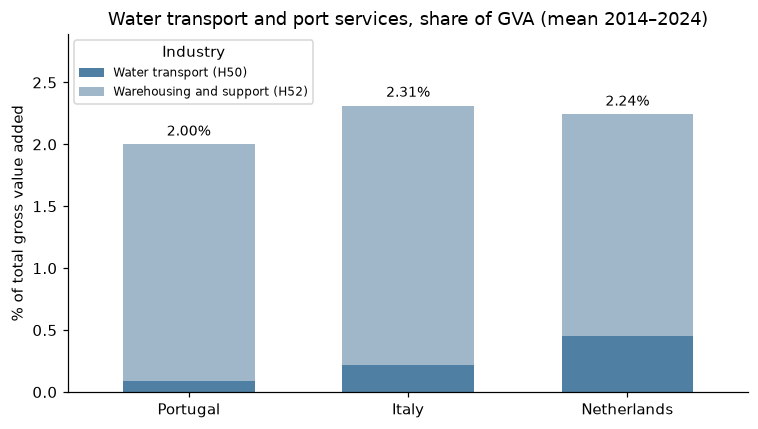

In [11]:
# ===== CHART A. Dependency: share of GVA, stacked bars (H50 + H52) =====
# Playground CORE 04 / CORE 09 – bars start at zero; the stack separates shipping (H50) from port services (H52)
STAT = "mean"   # choose: "mean", "median"
parts = pd.DataFrame({"Water transport (H50)": h50_share.agg(STAT),
                      "Warehousing and support (H52)": h52_share.agg(STAT)}).rename(index=NAMES)

ax = parts.plot(kind="bar", stacked=True, figsize=(7, 4), rot=0, width=0.6, color=["#4f7fa3", "#9fb7c9"])
for i, total in enumerate(parts.sum(axis=1)):
    ax.text(i, total * 1.02, f"{total:.2f}%", ha="center", va="bottom", fontsize=9)
ax.set(title=f"Water transport and port services, share of GVA ({STAT} 2014–2024)",
       xlabel="", ylabel="% of total gross value added", ylim=(0, parts.sum(axis=1).max() * 1.25))
ax.legend(title="Industry", loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

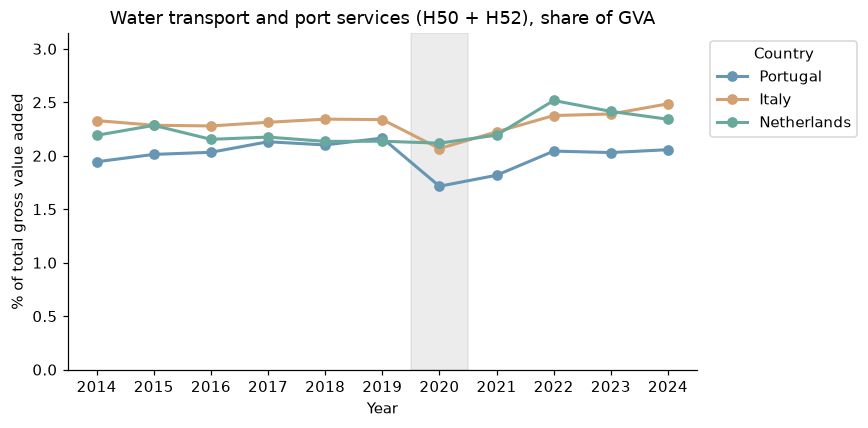

country  Portugal  Italy  Netherlands
year                                 
2014         1.94   2.33         2.19
2015         2.01   2.29         2.28
2016         2.03   2.28         2.15
2017         2.13   2.31         2.17
2018         2.10   2.34         2.13
2019         2.17   2.34         2.14
2020         1.71   2.07         2.12
2021         1.82   2.22         2.19
2022         2.04   2.38         2.52
2023         2.03   2.39         2.42
2024         2.06   2.49         2.34


In [12]:
# ===== CHART B. Dependency over time: H50 + H52 share of GVA =====
# Playground CORE 08 – one line per country, current prices so every year's share is consistent
fig, ax = plt.subplots(figsize=(8, 4))
for c in COUNTRIES:
    ax.plot(port_share.index, port_share[c], marker="o", linewidth=2, color=color_map[c], label=NAMES[c])
ax.axvspan(2019.5, 2020.5, color="grey", alpha=0.15)
ax.set(title="Water transport and port services (H50 + H52), share of GVA", xlabel="Year",
       ylabel="% of total gross value added", ylim=(0, port_share.max().max() * 1.25))
ax.set_xticks(port_share.index)
ax.legend(title="Country", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()
print(port_share.rename(columns=NAMES).round(2))

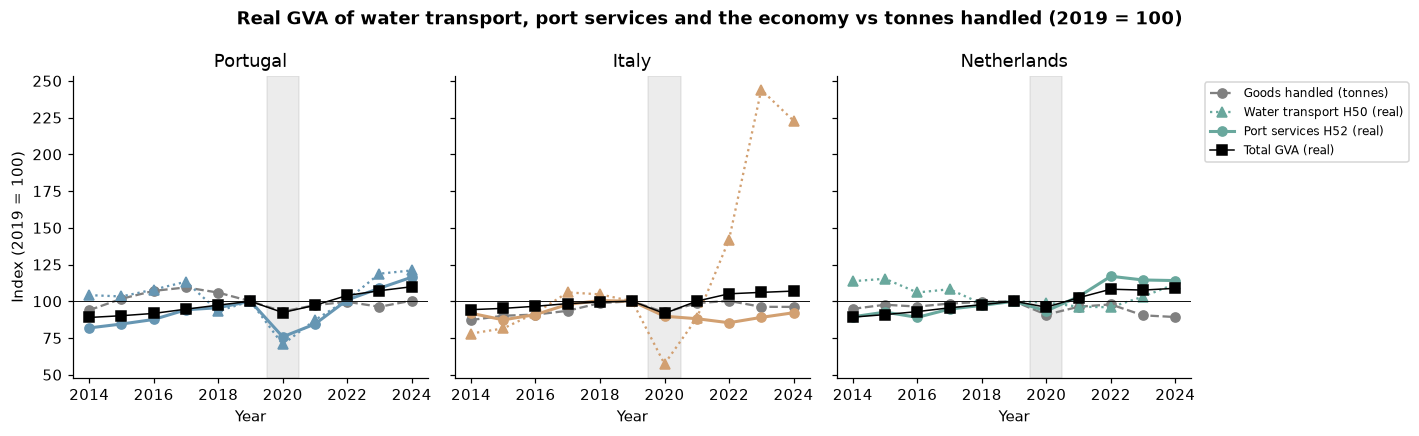

Change 2020 vs 2019 (%)
             tonnes  H50 real  H52 real  total GVA real
country                                                
Portugal       -7.0     -29.4     -24.2            -7.7
Italy          -7.6     -42.7     -10.2            -8.3
Netherlands    -9.1      -0.9      -6.6            -4.0
H50 + H52 (real) back to the 2019 level in: {'Portugal': 2022, 'Italy': 2023, 'Netherlands': 2021}


In [13]:
# ===== CHART C. Real change, index 2019 = 100: H50, H52, total economy and tonnes =====
# Playground BONUS 20 layout – one panel per country; GVA in chain-linked volumes (inflation removed)
def idx(t):
    return t / t.loc[2019] * 100

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, c in zip(axes, COUNTRIES):
    ax.plot(idx(tonnes).index, idx(tonnes)[c], color="grey", linestyle="--", marker="o", label="Goods handled (tonnes)")
    ax.plot(idx(h50_real).index, idx(h50_real)[c], color=color_map[c], linestyle=":", marker="^", label="Water transport H50 (real)")
    ax.plot(idx(h52_real).index, idx(h52_real)[c], color=color_map[c], linewidth=2, marker="o", label="Port services H52 (real)")
    ax.plot(idx(total_real).index, idx(total_real)[c], color="black", linewidth=1, marker="s", label="Total GVA (real)")
    ax.axhline(100, color="black", linewidth=0.6)
    ax.axvspan(2019.5, 2020.5, color="grey", alpha=0.15)
    ax.set(title=NAMES[c], xlabel="Year")
    ax.set_xticks([2014, 2016, 2018, 2020, 2022, 2024])
axes[0].set_ylabel("Index (2019 = 100)")
axes[2].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Real GVA of water transport, port services and the economy vs tonnes handled (2019 = 100)",
             fontweight="bold")
plt.tight_layout()
plt.show()

covid = pd.DataFrame({
    "tonnes": (tonnes.loc[2020] / tonnes.loc[2019] - 1) * 100,
    "H50 real": (h50_real.loc[2020] / h50_real.loc[2019] - 1) * 100,
    "H52 real": (h52_real.loc[2020] / h52_real.loc[2019] - 1) * 100,
    "total GVA real": (total_real.loc[2020] / total_real.loc[2019] - 1) * 100,
}).rename(index=NAMES).round(1)
print("Change 2020 vs 2019 (%)")
print(covid)
recovery = {NAMES[c]: next((y for y in port_real.index if y > 2020 and port_real.loc[y, c] >= port_real.loc[2019, c]),
                           "not by 2024") for c in COUNTRIES}
print("H50 + H52 (real) back to the 2019 level in:", recovery)

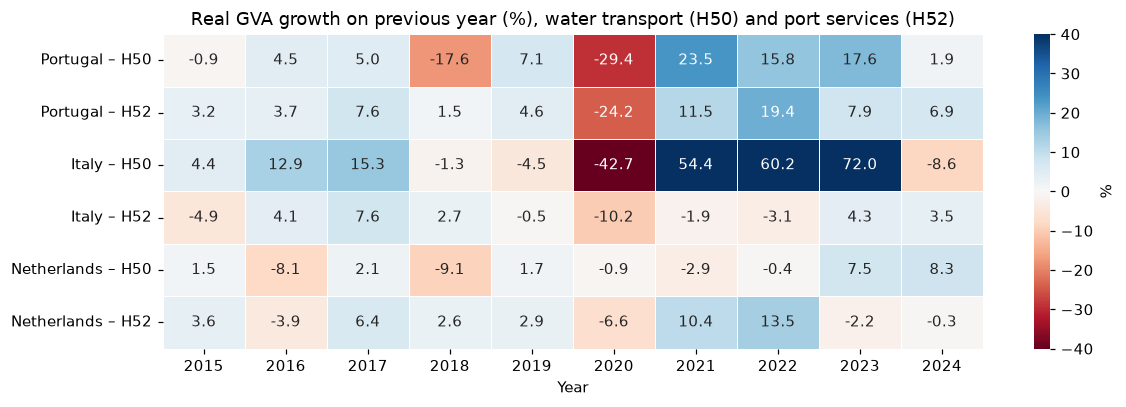

In [14]:
# ===== CHART D. Real growth heatmap: H50 and H52 by country and year =====
# Playground BONUS 17 – red = fall, blue = rise; shows which industry carried each shock
growth_rows = {}
for c in COUNTRIES:
    growth_rows[f"{NAMES[c]} – H50"] = h50_real[c].pct_change(fill_method=None) * 100
    growth_rows[f"{NAMES[c]} – H52"] = h52_real[c].pct_change(fill_method=None) * 100
growth_ind = pd.DataFrame(growth_rows).loc[2015:2024].T
lim = min(np.nanmax(np.abs(growth_ind.to_numpy())), 40)

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(growth_ind, annot=True, fmt=".1f", cmap="RdBu", center=0, vmin=-lim, vmax=lim,
            linewidths=0.5, cbar_kws={"label": "%"}, ax=ax)
ax.set(title="Real GVA growth on previous year (%), water transport (H50) and port services (H52)",
       xlabel="Year", ylabel="")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

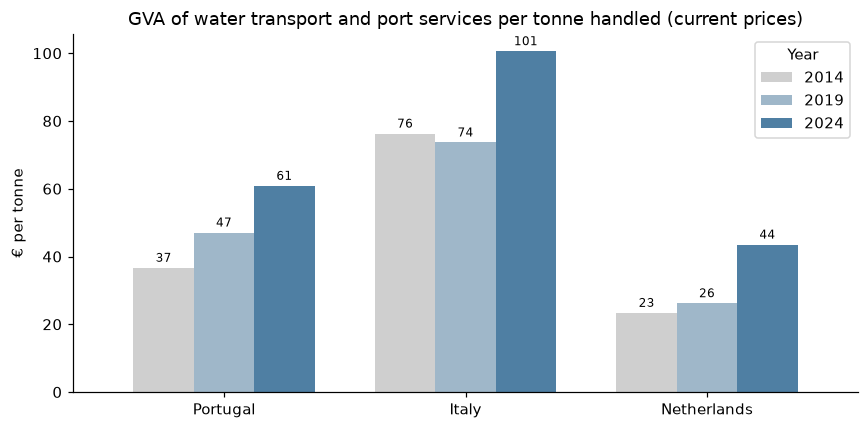

country  Portugal  Italy  Netherlands
year                                 
2014         37.0   76.0         23.0
2015         36.0   74.0         24.0
2016         36.0   75.0         24.0
2017         39.0   75.0         25.0
2018         41.0   74.0         25.0
2019         47.0   74.0         26.0
2020         38.0   66.0         28.0
2021         41.0   73.0         30.0
2022         51.0   84.0         38.0
2023         58.0   94.0         42.0
2024         61.0  101.0         44.0


In [15]:
# ===== CHART E. Value added per tonne handled =====
# Playground CORE 09 – pandas grouped bars; current prices, so part of the rise is inflation
PICK = [2014, 2019, 2024]
ax = eur_per_tonne.loc[PICK].T.rename(index=NAMES).plot(
    kind="bar", figsize=(8, 4), rot=0, width=0.75, color=["#cfcfcf", "#9fb7c9", "#4f7fa3"],
    title="GVA of water transport and port services per tonne handled (current prices)")
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{v:.0f}" if pd.notna(v) else "n/a" for v in cont.datavalues],
                 fontsize=8, padding=2)
ax.set(xlabel="", ylabel="€ per tonne")
ax.legend(title="Year")
plt.tight_layout()
plt.show()
print(eur_per_tonne.rename(columns=NAMES).round(0))


In [18]:
# ===== Clean table: one row per country and year, for the analysis and the Flask app =====
def long(t, name):
    return t.rename_axis(index="year", columns=None).reset_index().melt(id_vars="year", var_name="country", value_name=name)

panel = long(tonnes, "tonnes_ths")
for name, t in {"h50_cp_meur": h50_cp, "h52_cp_meur": h52_cp, "total_gva_cp_meur": total_cp,
                "h50_real_meur": h50_real, "h52_real_meur": h52_real, "total_gva_real_meur": total_real,
                "port_share_pct": port_share, "eur_per_tonne": eur_per_tonne}.items():
    panel = panel.merge(long(t, name), on=["year", "country"])
panel["country_name"] = panel["country"].map(NAMES)
panel.to_csv("ports_gva_2014_2024.csv", index=False)

print(panel.head(6))

   year country  tonnes_ths  h50_cp_meur  h52_cp_meur  total_gva_cp_meur  h50_real_meur  h52_real_meur  total_gva_real_meur  port_share_pct  eur_per_tonne country_name
0  2014      PT     80156.0        132.7       2805.3           151138.9          184.8         3107.7             168702.4        1.943907      36.653526     Portugal
1  2015      PT     86769.0        132.5       3008.8           156080.7          183.2         3208.2             170990.3        2.012613      36.203022     Portugal
2  2016      PT     91344.0        129.2       3158.4           161745.0          191.5         3325.9             173943.5        2.032582      35.991417     Portugal
3  2017      PT     93356.0        131.0       3472.1           169071.4          201.0         3577.2             179445.3        2.131111      38.595270     Portugal
4  2018      PT     90361.0        120.1       3602.5           177157.3          165.6         3629.6             184623.2        2.101296      41.196977     P